# Proyecto 5 — Retail: pronóstico de demanda con Dask

**Notebook autocontenido para Google Colab.** Compara AutoARIMA secuencial, `dask.delayed` en lotes de 50 y `dask.dataframe.map_partitions`, con 1,000 series sintéticas de 10 tiendas, 120 días de entrenamiento y 14 de prueba. Incluye exportación de resultados y gráficas.



## 1. Instalar dependencias

In [16]:
%pip -q install "dask[distributed,dataframe]" "statsforecast>=1.7" "pyarrow>=15" "polars>=1.0" "matplotlib>=3.8" "pandas>=2.0" "numpy>=1.26"

## 2. Preparar el proyecto y sus módulos
Estas celdas escriben los archivos Python en el entorno temporal de Colab. No necesitas montar Google Drive.

In [17]:
from pathlib import Path
ROOT=Path("/content/demand_par") if Path("/content").exists() else Path.cwd()/"demand_par"
for d in ["src", "data", "benchmarks/graficas"]:
    (ROOT/d).mkdir(parents=True, exist_ok=True)
print("Directorio:",ROOT)

Directorio: /content/demand_par


In [18]:
from pathlib import Path
(ROOT/"src"/"preprocess.py").write_text('"""Generación reproducible y preparación de datos de demanda."""\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nimport dask.dataframe as dd\n\ndef generar(ruta, n_series=1000, n_dias=120, horizonte=14, seed=2026):\n    rng=np.random.default_rng(seed)\n    dates=pd.date_range(\'2025-01-01\',periods=n_dias+horizonte,freq=\'D\')\n    partes=[]\n    for i in range(n_series):\n        t=np.arange(len(dates)); base=rng.uniform(15,90)\n        seasonal=rng.uniform(3,13)*np.sin(2*np.pi*t/7+rng.uniform(-1,1))\n        trend=rng.uniform(-0.05,0.09)*t\n        y=np.round(np.maximum(0,base+seasonal+trend+rng.normal(0,4,len(t))),2)\n        y[rng.choice(n_dias,size=2,replace=False)]=np.nan\n        partes.append(pd.DataFrame({\'unique_id\':f\'T{i%10:02d}_SKU{i:04d}\',\'ds\':dates,\'y\':y}))\n    path=Path(ruta);path.parent.mkdir(parents=True,exist_ok=True)\n    pd.concat(partes,ignore_index=True).to_parquet(path,index=False)\n    return path\n\ndef preparar(ruta, horizonte=14):\n    ddf=dd.read_parquet(str(ruta))\n    ddf[\'ds\']=dd.to_datetime(ddf[\'ds\'])\n    ddf[\'dia_semana\']=ddf[\'ds\'].dt.dayofweek\n    ddf[\'mes\']=ddf[\'ds\'].dt.month\n    df=ddf.compute().sort_values([\'unique_id\',\'ds\'])\n    series=[]; reales=[]\n    for uid,g in df.groupby(\'unique_id\',sort=True):\n        train=g.iloc[:-horizonte].copy();test=g.iloc[-horizonte:].copy()\n        mediana=train[\'y\'].median()\n        series.append((uid,train[\'y\'].fillna(mediana).fillna(0).to_numpy(dtype=\'float64\')))\n        reales.append(pd.DataFrame({\'unique_id\':uid,\'ds\':test[\'ds\'].to_numpy(),\n                                     \'actual\':test[\'y\'].fillna(mediana).to_numpy()}))\n    return series,pd.concat(reales,ignore_index=True)\n', encoding="utf-8")
print("Actualizado: preprocess.py")


Actualizado: preprocess.py


In [19]:
from pathlib import Path
(ROOT/"src"/"baseline_serial.py").write_text('"""Pronóstico secuencial AutoARIMA."""\nimport numpy as np\nfrom statsforecast.models import AutoARIMA\n\ndef pronosticar(item,horizonte=14):\n    uid,y=item\n    # Asegurar un vector numérico incluso si Dask entrega una lista o texto serializado.\n    if isinstance(y, str):\n        import ast as _ast\n        try:\n            y = _ast.literal_eval(y)\n        except (ValueError, SyntaxError):\n            import re\n            y = [float(v) for v in re.findall(r"[-+]?(?:\\d*\\.\\d+|\\d+\\.?\\d*)(?:[eE][-+]?\\d+)?", y)]\n    y = np.asarray(y, dtype=np.float64)\n    if y.ndim != 1 or y.size == 0 or not np.isfinite(y).all():\n        raise ValueError(f"Serie inválida para {uid}: forma={y.shape}")\n    model=AutoARIMA(season_length=7,max_p=1,max_q=1,max_P=0,max_Q=0,\n                    max_d=1,max_D=1,stepwise=True,approximation=True,\n                    allowmean=True,allowdrift=False)\n    fitted=model.fit(y)\n    return uid,np.asarray(fitted.predict(h=horizonte)[\'mean\'],dtype=float)\n\ndef ejecutar(series,horizonte=14):\n    return [pronosticar(item,horizonte) for item in series]\n', encoding="utf-8")
print("Actualizado: baseline_serial.py")


Actualizado: baseline_serial.py


In [20]:
from pathlib import Path
(ROOT/"src"/"forecast_dask.py").write_text('"""Dos estrategias Dask: delayed por lotes y dataframe.map_partitions."""\nimport time\nimport pandas as pd\nimport dask.dataframe as dd\nimport dask\nfrom dask import delayed\nfrom dask.distributed import Client, LocalCluster, wait\nfrom baseline_serial import pronosticar\n\n\ndef lote_pronosticos(lote, horizonte):\n    return [pronosticar(item, horizonte) for item in lote]\n\n\ndef predecir_particion(df, horizonte):\n    """Cada fila contiene una serie completa; una partición procesa varias series."""\n    rows = []\n    for row in df.itertuples(index=False):\n        uid, valores = pronosticar((row.unique_id, row.valores), horizonte)\n        rows.extend((uid, h, float(y)) for h, y in enumerate(valores))\n    return pd.DataFrame(rows, columns=[\'unique_id\', \'h\', \'pred\'])\n\n\ndef ejecutar(series, horizonte=14, tamano_lote=50, workers=4, hilos=2):\n    """Retorna resultados delayed, dataframe y tiempos medidos.\n\n    overhead_control_s mide un control de tareas triviales (proxy), NO la\n    comunicación pura del scheduler. La resta entre tiempos tampoco la aísla.\n    """\n    lotes = [series[i:i+tamano_lote] for i in range(0, len(series), tamano_lote)]\n    with LocalCluster(n_workers=workers, threads_per_worker=hilos,\n                      processes=False, dashboard_address=None) as cluster:\n        with Client(cluster) as client:\n            # Warm-up del scheduler, excluido de las mediciones.\n            client.submit(lambda: 1).result()\n            inicio = time.perf_counter()\n            control = client.compute([delayed(len)(lote) for lote in lotes])\n            wait(control)\n            _ = client.gather(control)\n            overhead_control = time.perf_counter()-inicio\n\n            inicio = time.perf_counter()\n            tareas = [delayed(lote_pronosticos)(lote, horizonte) for lote in lotes]\n            futuros = client.compute(tareas)\n            resultado_lotes = client.gather(futuros)\n            tiempo_delayed = time.perf_counter()-inicio\n            resultado_delayed = [x for lote in resultado_lotes for x in lote]\n\n            # Una fila = una serie; particiones ~ lotes de 50-100 series.\n            frame = pd.DataFrame({\'unique_id\':[uid for uid,_ in series],\n                                  \'valores\':[y for _,y in series]})\n            # Dask convierte columnas object a string automáticamente si\n            # dataframe.convert-string está activo. Eso rompe arrays NumPy.\n            with dask.config.set({"dataframe.convert-string": False}):\n                ddf = dd.from_pandas(frame, npartitions=len(lotes), sort=False)\n            meta = pd.DataFrame({\'unique_id\':pd.Series(dtype=\'str\'),\n                                 \'h\':pd.Series(dtype=\'int64\'),\n                                 \'pred\':pd.Series(dtype=\'float64\')})\n            inicio = time.perf_counter()\n            pred_df = ddf.map_partitions(predecir_particion, horizonte, meta=meta).compute()\n            tiempo_dataframe = time.perf_counter()-inicio\n    return resultado_delayed, pred_df, {\n        \'overhead_control_s\':overhead_control,\n        \'dask_delayed_s\':tiempo_delayed,\n        \'dask_dataframe_s\':tiempo_dataframe,\n        \'lotes\':len(lotes), \'workers\':workers, \'hilos_por_worker\':hilos,\n    }\n', encoding="utf-8")
print("Actualizado: forecast_dask.py")


Actualizado: forecast_dask.py


In [21]:
from pathlib import Path
(ROOT/"main.py").write_text('"""Ejemplo: python main.py --series 1000 --lote 50"""\nimport argparse, sys, time\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nROOT = Path(__file__).resolve().parent\nsys.path.insert(0, str(ROOT/\'src\'))\nfrom preprocess import generar, preparar\nfrom baseline_serial import ejecutar as serial\nfrom forecast_dask import ejecutar as paralelo\n\n\ndef evaluar(pred, reales):\n    combinado = reales.merge(pred, on=[\'unique_id\',\'ds\'], validate=\'one_to_one\')\n    if len(combinado) != len(reales) or combinado[\'pred\'].isna().any():\n        raise ValueError(\'Pronósticos incompletos\')\n    err = combinado[\'actual\'].to_numpy()-combinado[\'pred\'].to_numpy()\n    return float(np.mean(np.abs(err))), float(np.sqrt(np.mean(err**2)))\n\n\ndef tabla_pronosticos(resultados, inicio, dias):\n    rows = [(uid, inicio+pd.Timedelta(days=dias+h), float(v))\n            for uid, vals in resultados for h,v in enumerate(vals)]\n    return pd.DataFrame(rows, columns=[\'unique_id\',\'ds\',\'pred\'])\n\n\nif __name__ == \'__main__\':\n    p=argparse.ArgumentParser()\n    p.add_argument(\'--series\',type=int,default=1000)\n    p.add_argument(\'--dias\',type=int,default=120)\n    p.add_argument(\'--horizonte\',type=int,default=14)\n    p.add_argument(\'--lote\',type=int,default=50)\n    p.add_argument(\'--workers\',type=int,default=4)\n    p.add_argument(\'--hilos\',type=int,default=2)\n    args=p.parse_args()\n    if min(args.series,args.horizonte,args.lote,args.workers,args.hilos)<1 or args.dias<30:\n        p.error(\'Parámetros inválidos\')\n    ruta=generar(ROOT/\'data\'/\'demanda_sintetica.parquet\',args.series,args.dias,args.horizonte)\n    inicio=time.perf_counter()\n    series,reales=preparar(ruta,args.horizonte)\n    prep=time.perf_counter()-inicio\n    inicio=time.perf_counter()\n    r_serial=serial(series,args.horizonte)\n    t_serial=time.perf_counter()-inicio\n    r_delayed, r_ddf, tiempos=paralelo(series,args.horizonte,args.lote,args.workers,args.hilos)\n    fecha=pd.Timestamp(\'2025-01-01\')\n    serial_df=tabla_pronosticos(r_serial,fecha,args.dias)\n    delayed_df=tabla_pronosticos(r_delayed,fecha,args.dias)\n    dataframe_df=r_ddf.copy()\n    dataframe_df[\'ds\']=fecha+pd.to_timedelta(args.dias+dataframe_df[\'h\'],unit=\'D\')\n    comparacion=[]\n    for nombre,pron,t in [(\'Serial\',serial_df,t_serial),(\'Dask delayed\',delayed_df,tiempos[\'dask_delayed_s\']),(\'Dask DataFrame\',dataframe_df,tiempos[\'dask_dataframe_s\'])]:\n        mae,rmse=evaluar(pron,reales)\n        comparacion.append({\'metodo\':nombre,\'segundos\':t,\'speedup\':t_serial/t,\'MAE\':mae,\'RMSE\':rmse})\n    tabla=pd.DataFrame(comparacion)\n    assert np.allclose(tabla[\'MAE\'],tabla[\'MAE\'].iloc[0],atol=1e-5)\n    assert np.allclose(tabla[\'RMSE\'],tabla[\'RMSE\'].iloc[0],atol=1e-5)\n    carpeta=ROOT/\'benchmarks\'; carpeta.mkdir(exist_ok=True)\n    tabla.to_csv(carpeta/\'comparacion.csv\',index=False)\n    pd.DataFrame([{\'series\':args.series,\'preprocesamiento_s\':prep,**tiempos}]).to_csv(carpeta/\'overhead.csv\',index=False)\n    dataframe_df.to_csv(carpeta/\'pronosticos.csv\',index=False)\n    print(tabla.to_string(index=False))\n    print(\'\\nOverhead control (proxy, no comunicación aislada):\',round(tiempos[\'overhead_control_s\'],4),\'s\')\n', encoding="utf-8")
print("Actualizado: main.py")


Actualizado: main.py


## 3. Ejecutar el experimento
Comienza con 100 series para validar el entorno; después cambia `N_SERIES=1000` para el benchmark completo.


In [22]:
import subprocess, sys
N_SERIES=1000
TAMANO_LOTE=50
WORKERS=4
HILOS=2
comando=[sys.executable,"-u","main.py","--series",str(N_SERIES),"--lote",str(TAMANO_LOTE),"--workers",str(WORKERS),"--hilos",str(HILOS)]
print("Ejecutando:"," ".join(comando),flush=True)
resultado=subprocess.run(comando,cwd=str(ROOT),capture_output=True,text=True,check=False)
print("SALIDA:\n",resultado.stdout[-12000:])
if resultado.returncode:
    print("ERRORES (últimas líneas):\n",resultado.stderr[-12000:])
    raise RuntimeError(f"main.py terminó con código {resultado.returncode}")
print("Ejecución completada. Advertencias:\n",resultado.stderr[-1500:])


Ejecutando: /usr/bin/python3 -u main.py --series 1000 --lote 50 --workers 4 --hilos 2
SALIDA:
         metodo  segundos  speedup      MAE     RMSE
        Serial 29.703443 1.000000 4.528273 5.667518
  Dask delayed 46.166551 0.643397 4.528273 5.667518
Dask DataFrame 46.392092 0.640270 4.528273 5.667518

Overhead control (proxy, no comunicación aislada): 0.0484 s

Ejecución completada. Advertencias:
 ima.py:672: UserWarning: possible convergence problem: minimize gave code 2]
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsforecast/arima.py:672: UserWarning: possible convergence problem: minimize gave code 2]
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsforecast/arima.py:672: UserWarning: possible convergence problem: minimize gave code 2]
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsforecast/arima.py:672: UserWarning: possible convergence problem: minimize gave code 2]
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsforecast/

## 4. Resultados reales: tiempos, speedup y errores
Los archivos CSV se generan al terminar la ejecución. El tiempo de preprocesamiento se reporta por separado, de forma idéntica para los tres métodos.

In [23]:
import pandas as pd
comparacion=pd.read_csv(ROOT/"benchmarks/comparacion.csv")
overhead=pd.read_csv(ROOT/"benchmarks/overhead.csv")
display(comparacion.round(4))
display(overhead.round(4))

,metodo,segundos,speedup,MAE,RMSE
0,Serial,29.7034,1.0000,4.5283,5.6675
1,Dask delayed,46.1666,0.6434,4.5283,5.6675
2,Dask DataFrame,46.3921,0.6403,4.5283,5.6675


,series,preprocesamiento_s,overhead_control_s,dask_delayed_s,dask_dataframe_s,lotes,workers,hilos_por_worker
0,1000,1.1739,0.0484,46.1666,46.3921,20,4,2


## 5. Visualizar tiempos y speedup

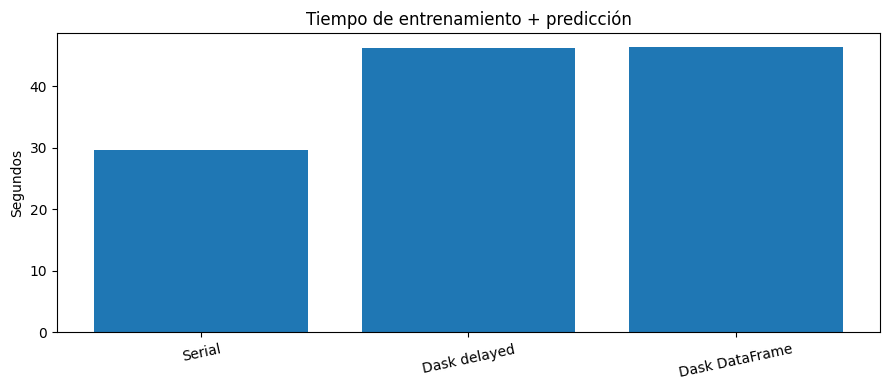

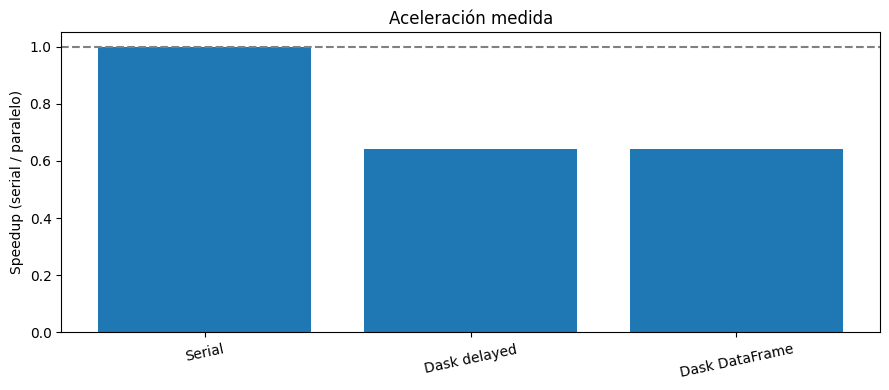

In [24]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(comparacion.metodo,comparacion.segundos)
ax.set(ylabel="Segundos",title="Tiempo de entrenamiento + predicción")
plt.xticks(rotation=12);plt.tight_layout();plt.savefig(ROOT/"benchmarks/graficas/tiempos.png",dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(comparacion.metodo,comparacion.speedup)
ax.axhline(1,linestyle="--",color="gray")
ax.set(ylabel="Speedup (serial / paralelo)",title="Aceleración medida")
plt.xticks(rotation=12);plt.tight_layout();plt.savefig(ROOT/"benchmarks/graficas/speedup.png",dpi=150);plt.show()

## 6. Comparar MAE y RMSE

,metodo,MAE,RMSE
0,Serial,4.5283,5.6675
1,Dask delayed,4.5283,5.6675
2,Dask DataFrame,4.5283,5.6675


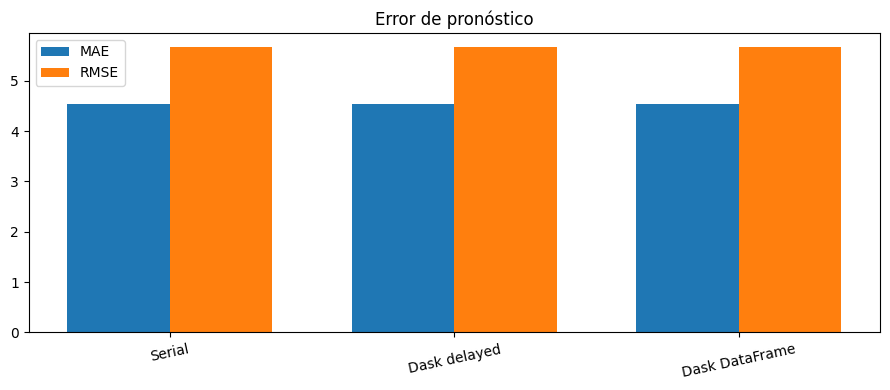

In [25]:
display(comparacion[["metodo","MAE","RMSE"]].round(4))
fig,ax=plt.subplots(figsize=(9,4))
x=range(len(comparacion));ax.bar([i-0.18 for i in x],comparacion.MAE,width=.36,label="MAE");ax.bar([i+.18 for i in x],comparacion.RMSE,width=.36,label="RMSE")
ax.set_xticks(list(x),comparacion.metodo,rotation=12);ax.legend();ax.set_title("Error de pronóstico")
plt.tight_layout();plt.savefig(ROOT/"benchmarks/graficas/errores.png",dpi=150);plt.show()

## 7. Pronóstico de una serie de ejemplo

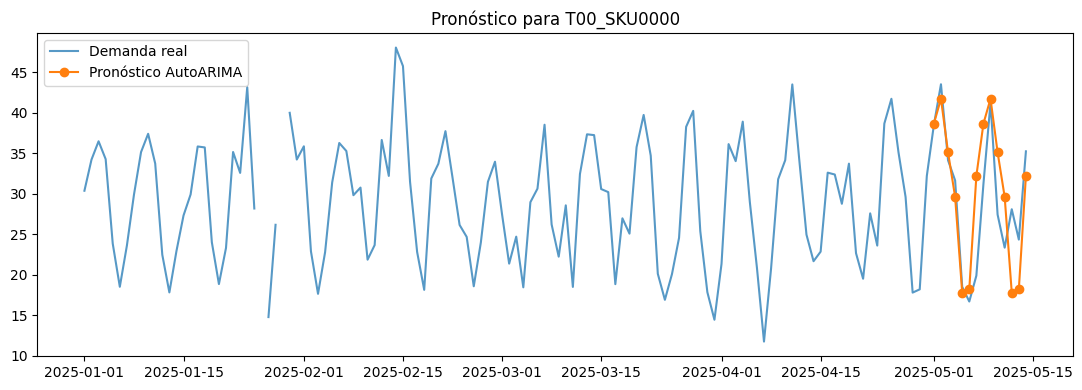

In [26]:
pron=pd.read_csv(ROOT/"benchmarks/pronosticos.csv",parse_dates=["ds"])
original=pd.read_parquet(ROOT/"data/demanda_sintetica.parquet")
uid=pron.unique_id.iloc[0]
real=original[original.unique_id==uid].sort_values("ds")
pred=pron[pron.unique_id==uid].sort_values("ds")
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(real.ds,real.y,label="Demanda real",alpha=.75)
ax.plot(pred.ds,pred.pred,label="Pronóstico AutoARIMA",marker="o")
ax.set_title("Pronóstico para "+uid);ax.legend();plt.tight_layout()
plt.savefig(ROOT/"benchmarks/graficas/ejemplo.png",dpi=150);plt.show()

## 8. Overhead: interpretación correcta
`overhead_control_s` mide el tiempo de enviar y resolver tareas triviales equivalentes al número de lotes, una **aproximación al costo de planificación**. No aísla el tráfico de red ni toda la comunicación. `dask_delayed_s` y `dask_dataframe_s` incluyen creación, planificación, transferencia y cálculo de sus respectivas tareas. En Colab los workers se ejecutan como hilos (`processes=False`) para evitar problemas de arranque de procesos; esto puede limitar la aceleración de modelos que compitan por el GIL.

In [27]:
fila=overhead.iloc[0]
print(f"Lotes: {int(fila.lotes)} | Workers: {int(fila.workers)} | Hilos por worker: {int(fila.hilos_por_worker)}")
print(f"Control del scheduler (proxy): {fila.overhead_control_s:.4f} s")
for r in comparacion.itertuples():
    print(f"{r.metodo}: {r.segundos:.2f} s, speedup {r.speedup:.2f}x, MAE {r.MAE:.3f}, RMSE {r.RMSE:.3f}")
print("Nota: un speedup menor que 1 significa que la versión paralela fue más lenta.")

Lotes: 20 | Workers: 4 | Hilos por worker: 2
Control del scheduler (proxy): 0.0484 s
Serial: 29.70 s, speedup 1.00x, MAE 4.528, RMSE 5.668
Dask delayed: 46.17 s, speedup 0.64x, MAE 4.528, RMSE 5.668
Dask DataFrame: 46.39 s, speedup 0.64x, MAE 4.528, RMSE 5.668
Nota: un speedup menor que 1 significa que la versión paralela fue más lenta.


## 9. Optimización experimental: workers, hilos y lotes

Se ejecutan **cuatro configuraciones** con el mismo dataset reproducible, horizonte y modelo AutoARIMA. Se mide el tiempo real de los tres métodos, MAE, RMSE y speedup; los resultados se guardan en `benchmarks/optimizacion.csv`. Los resultados anteriores no se sustituyen.

**Costo:** cada configuración vuelve a entrenar los modelos tres veces. Para explorar rápidamente usa `SERIES_OPT=100`; para comparar con el benchmark final utiliza `SERIES_OPT=1000`. Con 1,000 series puede tardar varios minutos. La cantidad de workers configurados no implica que Colab tenga esa cantidad de núcleos disponibles.

Las configuraciones propuestas son A (2 workers, 1 hilo, lote 50), B (2, 2, 100), C (4, 1, 50) y D (4, 2, 100). **La comparación es descriptiva**: se recomienda repetir cada prueba para obtener medidas más estables.


In [28]:
import subprocess, sys, time, pandas as pd
from pathlib import Path

SERIES_OPT = 1000
DIAS_OPT = 120
HORIZONTE_OPT = 14
CONFIGURACIONES = [
    ("A", 2, 1, 50),
    ("B", 2, 2, 100),
    ("C", 4, 1, 50),
    ("D", 4, 2, 100),
]

# main.py guarda sus resultados en archivos fijos. Leemos cada salida
# inmediatamente para conservar cada configuración sin sobrescribirla.
filas_opt = []
for nombre, workers, hilos, lote in CONFIGURACIONES:
    comando = [sys.executable, "-u", "main.py", "--series", str(SERIES_OPT),
               "--dias", str(DIAS_OPT), "--horizonte", str(HORIZONTE_OPT),
               "--lote", str(lote), "--workers", str(workers), "--hilos", str(hilos)]
    print(f"\nPrueba {nombre}: {workers} workers, {hilos} hilos/worker, lote {lote}", flush=True)
    t0 = time.perf_counter()
    with (ROOT / "benchmarks" / f"prueba_{nombre}_salida.log").open("w") as log:
        resultado = subprocess.run(comando, cwd=str(ROOT), stdout=log,
                                   stderr=subprocess.STDOUT, text=True, check=False)
    if resultado.returncode != 0:
        log_path = ROOT / "benchmarks" / f"prueba_{nombre}_salida.log"
        ultimas = log_path.read_text(errors="replace").splitlines()[-35:]
        print("\n".join(ultimas))
        raise RuntimeError(f"Falló la prueba {nombre} (código {resultado.returncode}); revisa {log_path}")
    tabla_prueba = pd.read_csv(ROOT / "benchmarks" / "comparacion.csv")
    overhead_prueba = pd.read_csv(ROOT / "benchmarks" / "overhead.csv").iloc[0]
    for _, fila in tabla_prueba.iterrows():
        filas_opt.append({"prueba": nombre, "series": SERIES_OPT,
                          "workers": workers, "hilos": hilos, "lote": lote,
                          "metodo": fila["metodo"], "segundos": fila["segundos"],
                          "speedup": fila["speedup"], "MAE": fila["MAE"],
                          "RMSE": fila["RMSE"],
                          "overhead_control_s": overhead_prueba["overhead_control_s"]})
    print(tabla_prueba[["metodo", "segundos", "speedup"]].round(3).to_string(index=False))

optimizacion = pd.DataFrame(filas_opt)
optimizacion.to_csv(ROOT / "benchmarks" / "optimizacion.csv", index=False)
display(optimizacion.round(4))



Prueba A: 2 workers, 1 hilos/worker, lote 50
        metodo  segundos  speedup
        Serial    28.902    1.000
  Dask delayed    47.525    0.608
Dask DataFrame    45.678    0.633

Prueba B: 2 workers, 2 hilos/worker, lote 100
        metodo  segundos  speedup
        Serial    29.147    1.000
  Dask delayed    45.720    0.637
Dask DataFrame    47.610    0.612

Prueba C: 4 workers, 1 hilos/worker, lote 50
        metodo  segundos  speedup
        Serial    29.207    1.000
  Dask delayed    47.551    0.614
Dask DataFrame    47.136    0.620

Prueba D: 4 workers, 2 hilos/worker, lote 100
        metodo  segundos  speedup
        Serial    29.529    1.000
  Dask delayed    46.583    0.634
Dask DataFrame    46.228    0.639


,prueba,series,workers,hilos,lote,metodo,segundos,speedup,MAE,RMSE,overhead_control_s
0,A,1000,2,1,50,Serial,28.9021,1.0000,4.5283,5.6675,0.0647
1,A,1000,2,1,50,Dask delayed,47.5251,0.6081,4.5283,5.6675,0.0647
2,A,1000,2,1,50,Dask DataFrame,45.6783,0.6327,4.5283,5.6675,0.0647
3,B,1000,2,2,100,Serial,29.1468,1.0000,4.5283,5.6675,0.0334
4,B,1000,2,2,100,Dask delayed,45.7205,0.6375,4.5283,5.6675,0.0334
5,B,1000,2,2,100,Dask DataFrame,47.6096,0.6122,4.5283,5.6675,0.0334
6,C,1000,4,1,50,Serial,29.2068,1.0000,4.5283,5.6675,0.0484
7,C,1000,4,1,50,Dask delayed,47.5513,0.6142,4.5283,5.6675,0.0484
8,C,1000,4,1,50,Dask DataFrame,47.1355,0.6196,4.5283,5.6675,0.0484
9,D,1000,4,2,100,Serial,29.5292,1.0000,4.5283,5.6675,0.0345


### Gráficas comparativas y mejor configuración observada

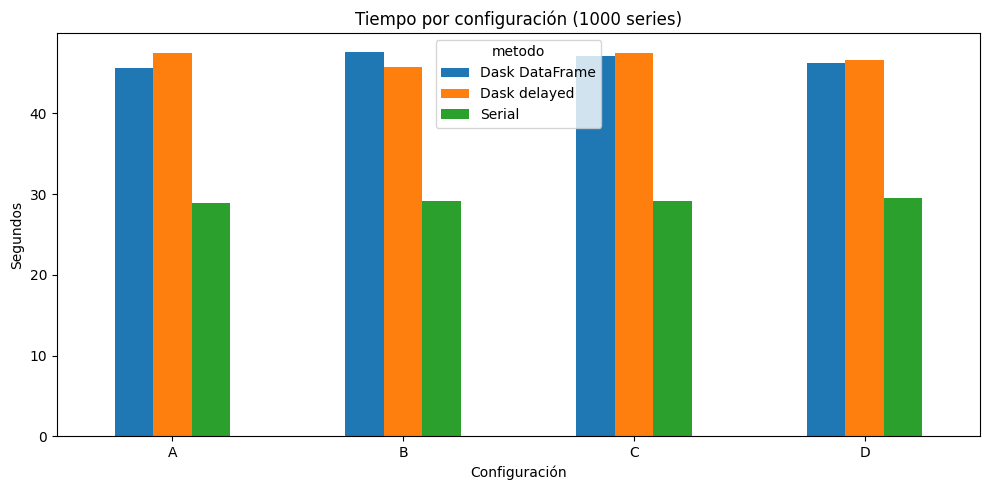

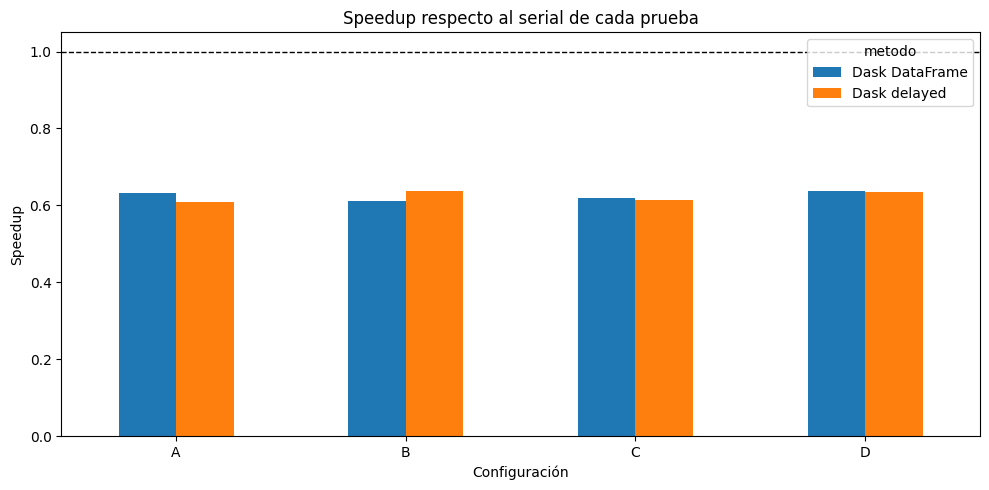

Mayor speedup observado: 0.639x | prueba D | Dask DataFrame
Si el speedup es menor que 1, la ejecución paralela sigue siendo más lenta.
Estas mediciones corresponden a una sola ejecución por configuración; no son promedios estadísticos.


In [29]:
import matplotlib.pyplot as plt

resumen_opt = optimizacion.pivot(index="prueba", columns="metodo", values="segundos")
ax = resumen_opt.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set(title=f"Tiempo por configuración ({SERIES_OPT} series)", xlabel="Configuración", ylabel="Segundos")
plt.tight_layout()
plt.savefig(ROOT / "benchmarks" / "graficas" / "optimizacion_tiempos.png", dpi=150)
plt.show()

paralelos = optimizacion[optimizacion.metodo != "Serial"].copy()
ax = paralelos.pivot(index="prueba", columns="metodo", values="speedup").plot(kind="bar", figsize=(10, 5), rot=0)
ax.axhline(1, color="black", linestyle="--", linewidth=1, label="Sin aceleración")
ax.set(title="Speedup respecto al serial de cada prueba", xlabel="Configuración", ylabel="Speedup")
plt.tight_layout()
plt.savefig(ROOT / "benchmarks" / "graficas" / "optimizacion_speedup.png", dpi=150)
plt.show()

mejor = paralelos.loc[paralelos.speedup.idxmax()]
print(f"Mayor speedup observado: {mejor.speedup:.3f}x | prueba {mejor.prueba} | {mejor.metodo}")
print("Si el speedup es menor que 1, la ejecución paralela sigue siendo más lenta.")
print("Estas mediciones corresponden a una sola ejecución por configuración; no son promedios estadísticos.")


## 10. ZIP con resultados obtenidos


In [30]:
import shutil
archivo=shutil.make_archive(str(ROOT/"benchmarks_resultados"),"zip",root_dir=ROOT,base_dir="benchmarks")
print("ZIP de resultados:",archivo)
try:
    from google.colab import files
    files.download(archivo)
except ImportError:
    print("Fuera de Colab: abre la ruta mostrada.")

ZIP de resultados: /content/demand_par/benchmarks_resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusiones para completar tras ejecutar
- **Rendimiento:** interpreta los speedups medidos y si Dask supera al baseline.
- **Calidad:** compara MAE y RMSE; al usar el mismo modelo y datos deberían ser prácticamente iguales.
- **Overhead:** explica si el costo de planificación y el tamaño de lote justifican la paralelización.
- **Limitaciones:** los datos son sintéticos, el runtime Colab es variable y el modo hilos puede limitar la concurrencia.

**No inventes resultados:** utiliza los CSV generados para redactar la conclusión final.